# FIFA World Cup 2026 – Objective 2

This is our final linear regression notebook. It uses the variables tested by Mel, Manish and me. I put the prepared data together for two models: one for goal difference (2.1) and one for team goals (2.2). Both models have eight predictors.


## 1. Read the data

I saved the merged datasets in `Outputs`. I matched Manish’s rows using the date and both team names, since the match IDs in our files are not in the same order. The original source CSVs are unchanged.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

HERE = Path.cwd()
output_dir = HERE / 'Outputs'
output_dir.mkdir(exist_ok=True)

df21 = pd.read_csv(output_dir / 'Objective2_1_Integrated_104.csv')
df22 = pd.read_csv(output_dir / 'Objective2_2_Integrated_208.csv')

x21 = ['X1_Past7_WinRate_Diff', 'X2_Past7_GoalsConceded_Diff',
       'X3_WC_Participations_Diff', 'X4_MostExpPlayer_Pre2026_Diff',
       'PreMatch_Unbeaten_Rate', 'PreMatch_Elo_Difference',
       'X1_PreMatch_GD_Difference', 'X2_PreMatch_Win_Rate_Difference']
x22 = ['PreMatch_Elo_Difference', 'Pre2026_WC_Participation_Difference',
       'Opponent_Loss_Rate_Last7', 'PreMatch_Unbeaten_Rate_Last7',
       'X5_Prior_WC_Team_AvgGoals', 'X6_Prior_WC_Opp_AvgConceded',
       'X7_Avg_SquadAge_Team', 'X8_DaysSincePrevInternational_Team']
y21, y22 = 'Y_GoalDifference', 'Y_TeamGoals'

for df, cols, target, expected in [(df21,x21,y21,104),(df22,x22,y22,208)]:
    assert len(df) == expected and df['Match_ID'].nunique() == 104
    assert len(cols) == 8 and set(cols + [target]).issubset(df.columns)
    df['Date'] = pd.to_datetime(df['Date'])
    for c in cols + [target]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    assert df[target].notna().all()

print('Objective 2.1:', df21.shape, '— 8 predictors')
print('Objective 2.2:', df22.shape, '— 8 predictors')
print('Missing values, 2.1:')
print(df21[x21].isna().sum())
print('Missing values, 2.2:')
print(df22[x22].isna().sum())

Objective 2.1: (104, 13) — 8 predictors
Objective 2.2: (208, 14) — 8 predictors
Missing values, 2.1:
X1_Past7_WinRate_Diff               0
X2_Past7_GoalsConceded_Diff         0
X3_WC_Participations_Diff           0
X4_MostExpPlayer_Pre2026_Diff       0
PreMatch_Unbeaten_Rate              0
PreMatch_Elo_Difference             0
X1_PreMatch_GD_Difference          24
X2_PreMatch_Win_Rate_Difference    24
dtype: int64
Missing values, 2.2:
PreMatch_Elo_Difference                 0
Pre2026_WC_Participation_Difference     0
Opponent_Loss_Rate_Last7                0
PreMatch_Unbeaten_Rate_Last7            0
X5_Prior_WC_Team_AvgGoals              48
X6_Prior_WC_Opp_AvgConceded            48
X7_Avg_SquadAge_Team                    0
X8_DaysSincePrevInternational_Team      0
dtype: int64


## 2. Scatterplots and correlations

First, I plotted the predictors against each target and checked Pearson correlation. Where an early match has no previous match data, the scatterplot just uses the rows that are available.


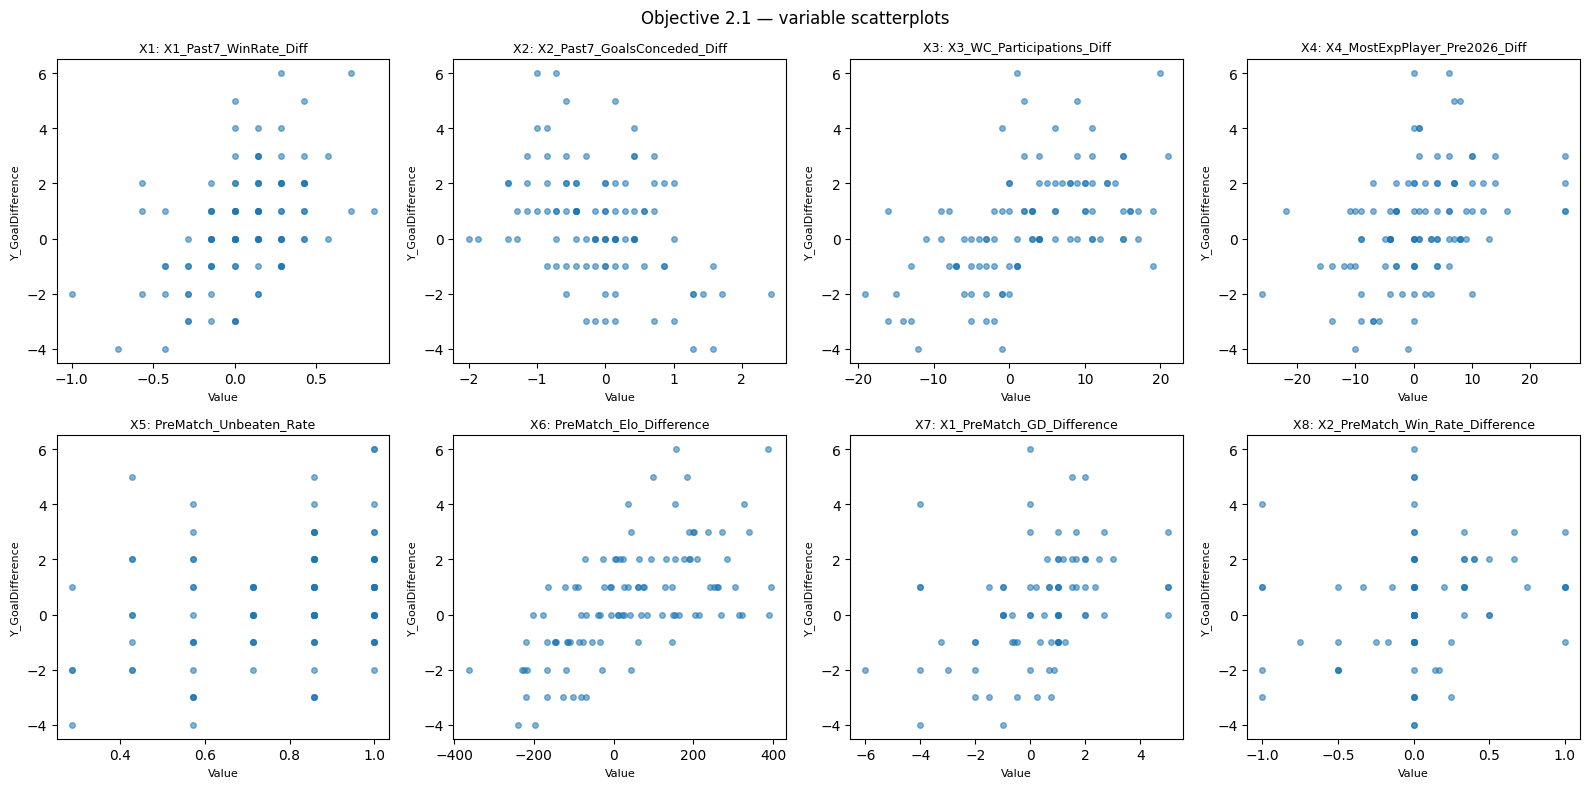

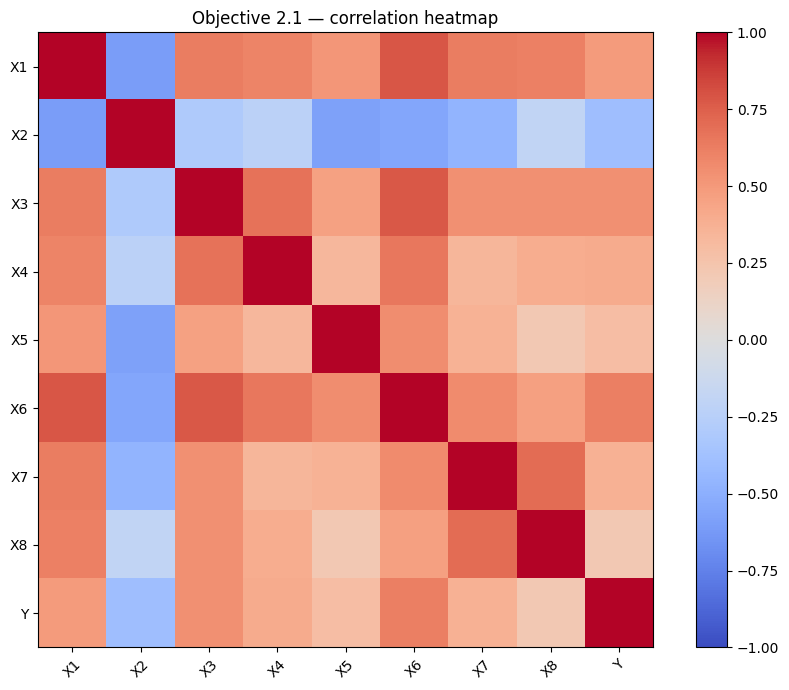

,Correlation with target
X1_Past7_WinRate_Diff,0.489
X2_Past7_GoalsConceded_Diff,-0.393
X3_WC_Participations_Diff,0.546
X4_MostExpPlayer_Pre2026_Diff,0.406
PreMatch_Unbeaten_Rate,0.292
PreMatch_Elo_Difference,0.619
X1_PreMatch_GD_Difference,0.371
X2_PreMatch_Win_Rate_Difference,0.212


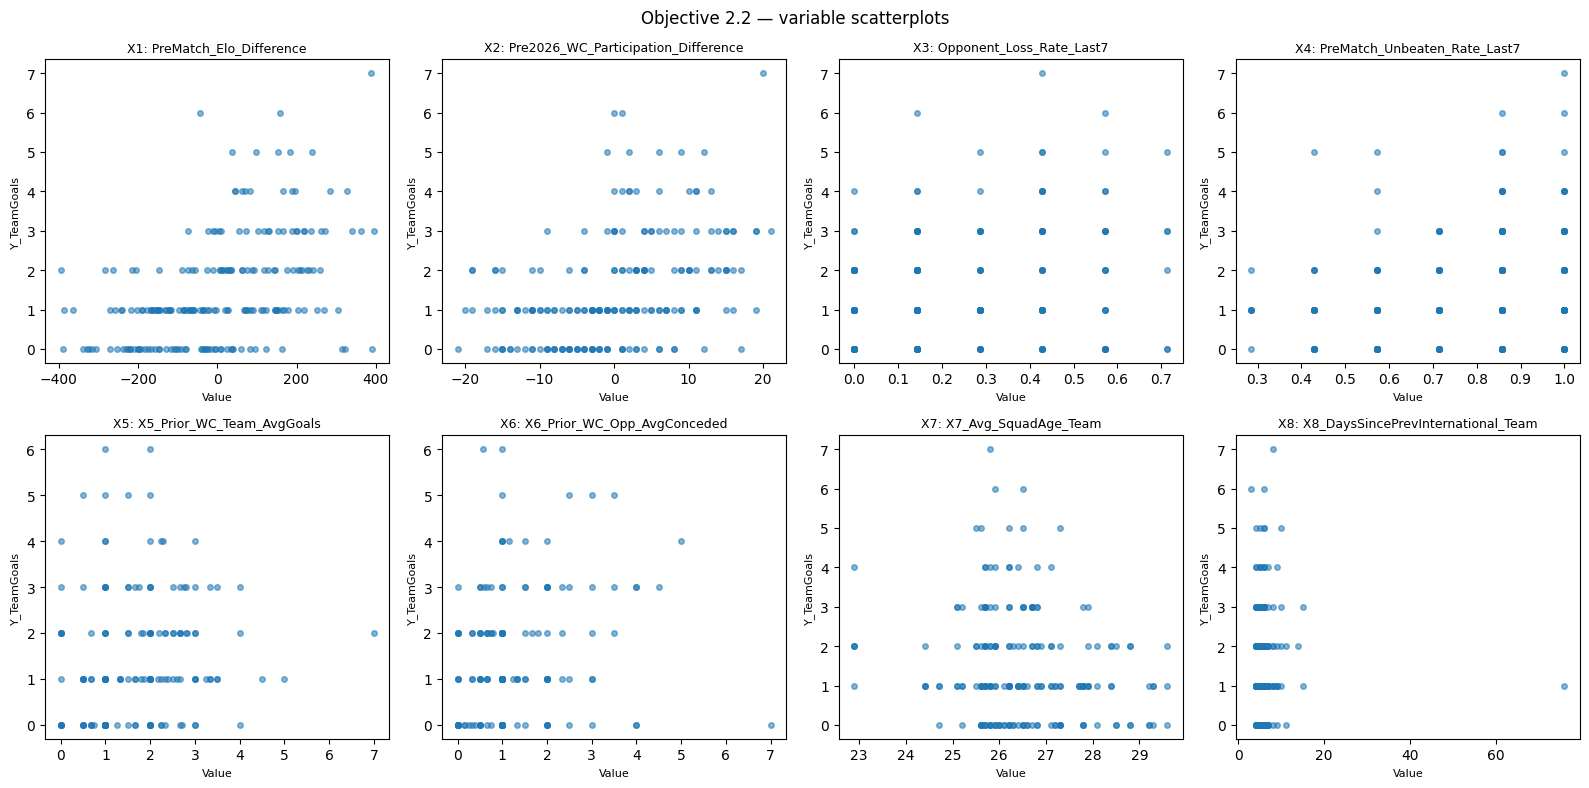

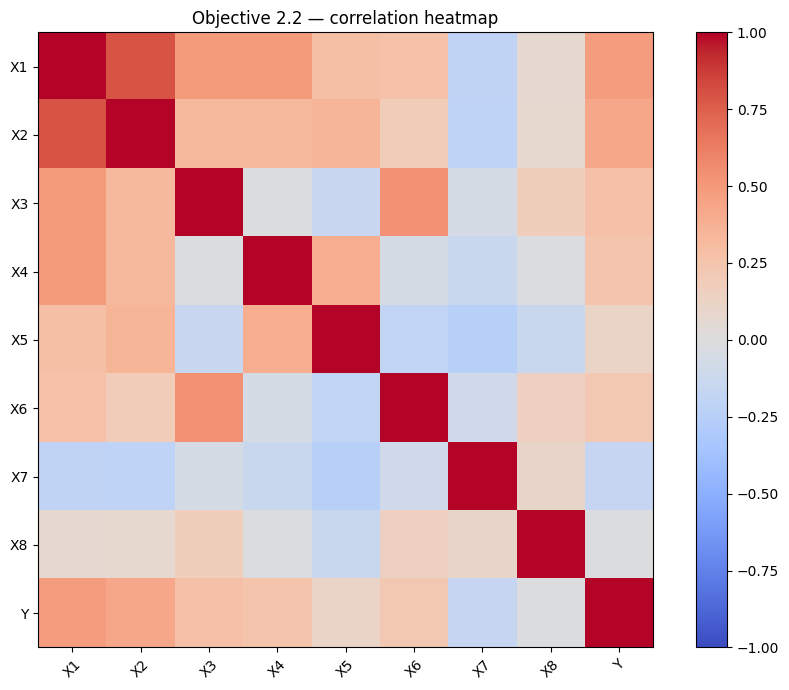

,Correlation with target
PreMatch_Elo_Difference,0.477
Pre2026_WC_Participation_Difference,0.428
Opponent_Loss_Rate_Last7,0.278
PreMatch_Unbeaten_Rate_Last7,0.247
X5_Prior_WC_Team_AvgGoals,0.111
X6_Prior_WC_Opp_AvgConceded,0.215
X7_Avg_SquadAge_Team,-0.171
X8_DaysSincePrevInternational_Team,-0.013


In [2]:
def plots_and_correlations(data, features, target, label):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for i, col in enumerate(features):
        xy = data[[col, target]].dropna()
        ax = axes.flat[i]
        ax.scatter(xy[col], xy[target], s=16, alpha=0.55)
        ax.set_title(f'X{i+1}: {col}', fontsize=9)
        ax.set_xlabel('Value', fontsize=8)
        ax.set_ylabel(target, fontsize=8)
    fig.suptitle(f'Objective {label} — variable scatterplots')
    fig.tight_layout()
    fig.savefig(output_dir / f'Objective{label.replace(".", "_")}_Variable_Scatterplots.png', dpi=170)
    plt.show()

    corr = data[features + [target]].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(9), [f'X{i+1}' for i in range(8)] + ['Y'], rotation=45)
    ax.set_yticks(range(9), [f'X{i+1}' for i in range(8)] + ['Y'])
    fig.colorbar(im, ax=ax)
    ax.set_title(f'Objective {label} — correlation heatmap')
    fig.tight_layout()
    fig.savefig(output_dir / f'Objective{label.replace(".", "_")}_Correlation_Heatmap.png', dpi=170)
    plt.show()
    display(corr[target].drop(target).round(3).to_frame('Correlation with target'))

plots_and_correlations(df21, x21, y21, '2.1')
plots_and_correlations(df22, x22, y22, '2.2')

## 3. Train/test split comparison

I tried three random match-level splits (60/40, 70/30 and 80/20), as well as an 80/20 split based on match date. Both sides of a match stay in the same set for 2.2. Missing values are filled with medians from the training set only.


In [3]:
def fit_test(df, features, target, test_size=0.2, chronological=False):
    matches = df[['Match_ID','Date']].drop_duplicates('Match_ID').sort_values(['Date','Match_ID'])
    if chronological:
        point = int(len(matches) * (1-test_size))
        train_ids = set(matches.iloc[:point]['Match_ID'])
        test_ids = set(matches.iloc[point:]['Match_ID'])
    else:
        a, b = train_test_split(matches['Match_ID'].to_numpy(), test_size=test_size, random_state=42)
        train_ids, test_ids = set(a), set(b)
    assert not train_ids.intersection(test_ids)
    train = df[df.Match_ID.isin(train_ids)].copy()
    test = df[df.Match_ID.isin(test_ids)].copy()
    fill = train[features].median().fillna(0)
    model = LinearRegression()
    model.fit(train[features].fillna(fill), train[target])
    actual = test[target].to_numpy()
    pred = model.predict(test[features].fillna(fill))
    return {'Train rows':len(train),'Test rows':len(test),
            'MAE':mean_absolute_error(actual,pred),
            'RMSE':np.sqrt(mean_squared_error(actual,pred)),
            'R2':r2_score(actual,pred)}, model, actual, pred, train, test

results = []
final_models = {}
for label, data, cols, target in [('2.1',df21,x21,y21),('2.2',df22,x22,y22)]:
    for test_size in [0.4, 0.3, 0.2]:
        result, *_ = fit_test(data, cols, target, test_size)
        results.append({'Objective':label,'Split':f'{int((1-test_size)*100)}/{int(test_size*100)}',**result})
    result, model, actual, pred, train, test = fit_test(data,cols,target,0.2,chronological=True)
    results.append({'Objective':label,'Split':'Chronological 80/20',**result})
    final_models[label]=(model,actual,pred,train,test,cols,target)

scores=pd.DataFrame(results)
display(scores.round(3))
scores.to_csv(output_dir / 'Train_Test_Split_Results.csv', index=False)

,Objective,Split,Train rows,Test rows,MAE,RMSE,R2
0,2.1,60/40,62,42,1.412,1.804,0.316
1,2.1,70/30,72,32,1.389,1.788,0.353
2,2.1,80/20,83,21,1.458,1.878,0.360
3,2.1,Chronological 80/20,83,21,1.185,1.488,0.056
4,2.2,60/40,124,84,0.915,1.189,0.242
5,2.2,70/30,144,64,0.925,1.215,0.273
6,2.2,80/20,166,42,0.919,1.204,0.324
7,2.2,Chronological 80/20,166,42,0.967,1.290,0.035


## 4. Five-fold cross-validation

I used GroupKFold on the training matches from the chronological split. It keeps the two rows for one match together and gives five validation results to compare.


In [4]:
cv_rows=[]
for label in ['2.1','2.2']:
    model, actual, pred, train, test, cols, target = final_models[label]
    splitter=GroupKFold(n_splits=5)
    X=train[cols]
    y=train[target]
    for fold, (a,b) in enumerate(splitter.split(X,y,groups=train['Match_ID']),start=1):
        reg=make_pipeline(SimpleImputer(strategy='median'),LinearRegression())
        reg.fit(X.iloc[a],y.iloc[a])
        forecast=reg.predict(X.iloc[b])
        cv_rows.append({'Objective':label,'Fold':fold,
                        'Training matches':train.iloc[a].Match_ID.nunique(),
                        'Validation matches':train.iloc[b].Match_ID.nunique(),
                        'MAE':mean_absolute_error(y.iloc[b],forecast),
                        'RMSE':np.sqrt(mean_squared_error(y.iloc[b],forecast)),
                        'R2':r2_score(y.iloc[b],forecast)})
cv=pd.DataFrame(cv_rows)
display(cv.round(3))
display(cv.groupby('Objective')[['MAE','RMSE','R2']].mean().round(3))
cv.to_csv(output_dir / 'GroupKFold_5Fold_Results.csv', index=False)

,Objective,Fold,Training matches,Validation matches,MAE,RMSE,R2
0,2.1,1,66,17,1.183,1.461,0.304
1,2.1,2,66,17,1.569,2.128,-0.027
2,2.1,3,66,17,1.569,1.832,0.209
3,2.1,4,67,16,1.205,1.530,0.096
4,2.1,5,67,16,1.357,1.655,0.356
5,2.2,1,66,17,0.982,1.193,0.047
6,2.2,2,66,17,1.028,1.419,0.248
7,2.2,3,66,17,0.904,1.148,0.259
8,2.2,4,67,16,0.994,1.271,-0.285
9,2.2,5,67,16,0.881,1.241,0.291


,MAE,RMSE,R2
Objective,,,
2.1,1.377,1.721,0.188
2.2,0.958,1.254,0.112


## 5. Actual vs predicted and residuals

These plots help me check where the final models predict too high or too low.


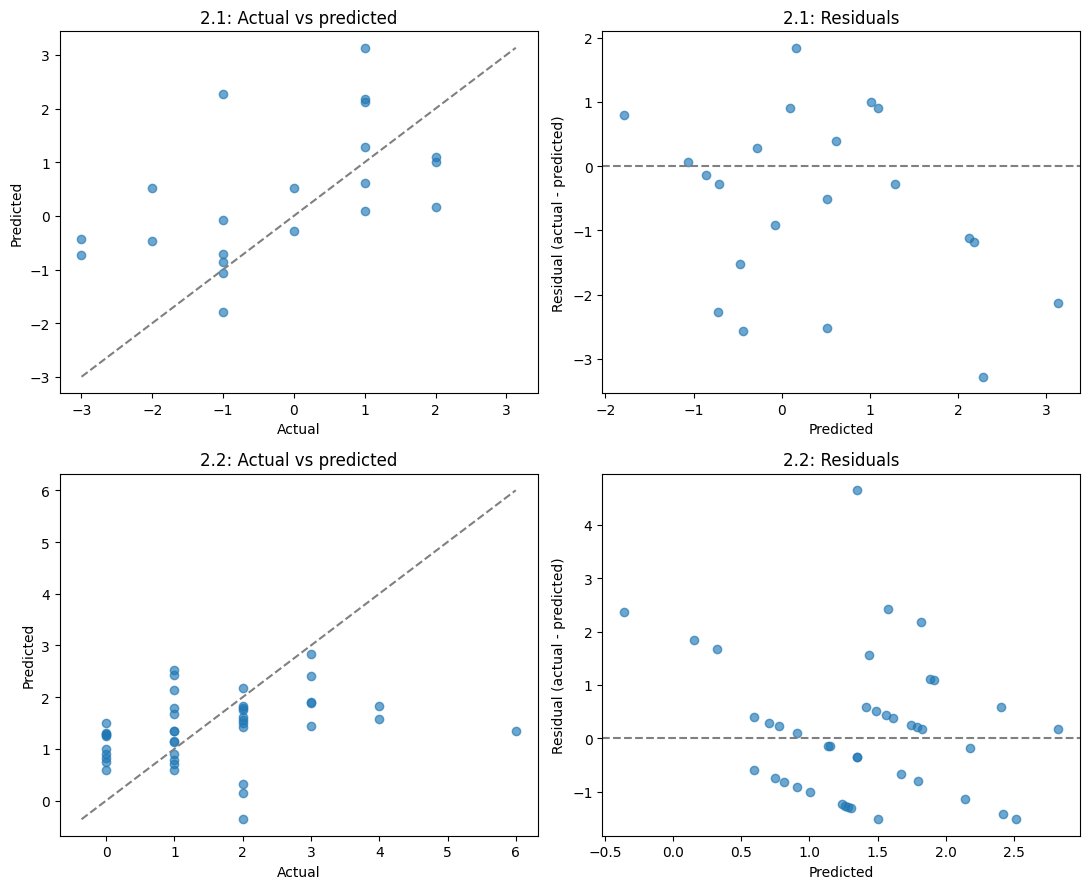

In [5]:
fig, axes = plt.subplots(2,2,figsize=(11,9))
for i,label in enumerate(['2.1','2.2']):
    model,actual,pred,train,test,cols,target=final_models[label]
    ax=axes[i,0]
    ax.scatter(actual,pred,alpha=0.65)
    low=min(actual.min(),pred.min());high=max(actual.max(),pred.max())
    ax.plot([low,high],[low,high],'--',color='grey')
    ax.set(xlabel='Actual',ylabel='Predicted',title=f'{label}: Actual vs predicted')
    ax=axes[i,1]
    ax.scatter(pred,actual-pred,alpha=0.65)
    ax.axhline(0,color='grey',linestyle='--')
    ax.set(xlabel='Predicted',ylabel='Residual (actual - predicted)',title=f'{label}: Residuals')
fig.tight_layout()
fig.savefig(output_dir / 'Objective2_Final_Predictions_and_Residuals.png',dpi=180)
plt.show()

## 6. Notes before the report

I did not edit the original source CSVs. The combined datasets and model results are saved in `Outputs`. We still need to confirm the snapshot date for the age and World Cup participation figures in `Age.csv`. Also, some of the recent-form variables use earlier matches in the 2026 tournament, so they are pre-match only when the prediction is made before that specific game.
